### Có dùng AI hỗ trợ

- **Công cụ:** Copilot SDK trong VS Code.
- **Mục đích:** Hỗ trợ triển khai và kiểm thử mã thuật toán, xây dựng khung thí nghiệm, quét tham số và vẽ biểu đồ.
- **Prompt đã dùng:** “Tạo mẫu độc lập có chỗ điền hàm/đường dẫn”.
- **Đã kiểm tra/sửa:** Mã thuật toán được triển khai trong `image_algorithms.py`; cần đọc, kiểm thử và giải thích được các phần cài đặt trước khi nộp.

Các lời gọi OpenCV trong notebook chỉ dùng để đọc ảnh, tạo dữ liệu kiểm thử hoặc làm mốc tham chiếu trong thí nghiệm; không thay thế phần cài đặt thuật toán bắt buộc.

# Khung thí nghiệm CLAHE, ngưỡng thích nghi và Hough đa tỉ lệ

Các thuật toán NumPy được cài trong `image_algorithms.py` và được nối qua các adapter `my_*`. OpenCV chỉ dùng để đọc ảnh, tạo dữ liệu kiểm thử hoặc làm mốc tham chiếu được ghi rõ. Không dùng kết quả giả lập làm kết quả thí nghiệm. Đồ thị thời gian là đo đạc thực nghiệm, không tự nó chứng minh độ phức tạp.

In [4]:
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from image_algorithms import adaptive_threshold, clahe, hough_multiscale

# Đường dẫn ảnh mẫu trong thư mục dự án.
IMAGE_DIR = Path(r"E:\Tai lieu hoc tap\Xử Lý Ảnh và Thị Giác Máy Tính")
IMAGE_PATH_1 = IMAGE_DIR / "test_image_1.jpg"  # Ánh sáng không đều
IMAGE_PATH_2 = IMAGE_DIR / "test_image_2.jpg"  # Văn bản
IMAGE_PATH_3 = IMAGE_DIR / "test_image_3.jpg"  # Các đường thẳng


def load_gray_image(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {path.resolve()}")
    image_bytes = np.fromfile(path, dtype=np.uint8)
    image = cv2.imdecode(image_bytes, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return image


def my_clahe(img, grid=(8, 8), clip_limit=2.0):
    return clahe(img, grid=grid, clip_limit=clip_limit)


def my_adaptive_threshold(img, radius=15, method="bradley", t=0.15, k=0.34):
    return adaptive_threshold(img, radius=radius, method=method, t=t, k=k)


def my_hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8):
    return hough_multiscale(edges, grad_dir, n_levels=n_levels, refine_factor=refine_factor)

## Thí nghiệm 1 — CLAHE

Quét riêng `clip_limit` và `grid` trên ảnh ánh sáng không đều; sau đó so sánh kéo giãn tương phản tuyến tính, hiệu chỉnh gamma, HE toàn cục và CLAHE tự cài trên cùng ảnh, kèm histogram. OpenCV chỉ được dùng làm mốc tham chiếu trong phần đối chiếu.

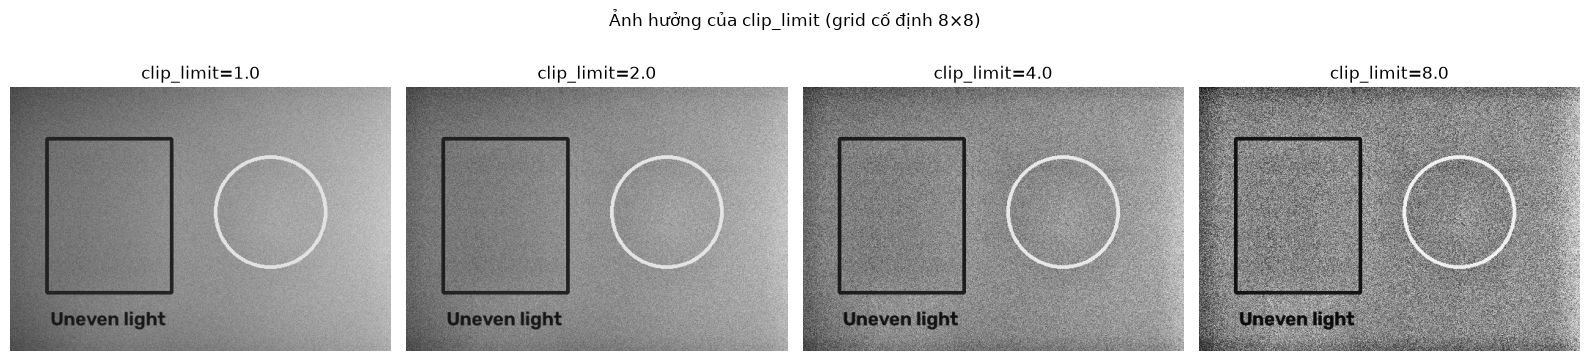

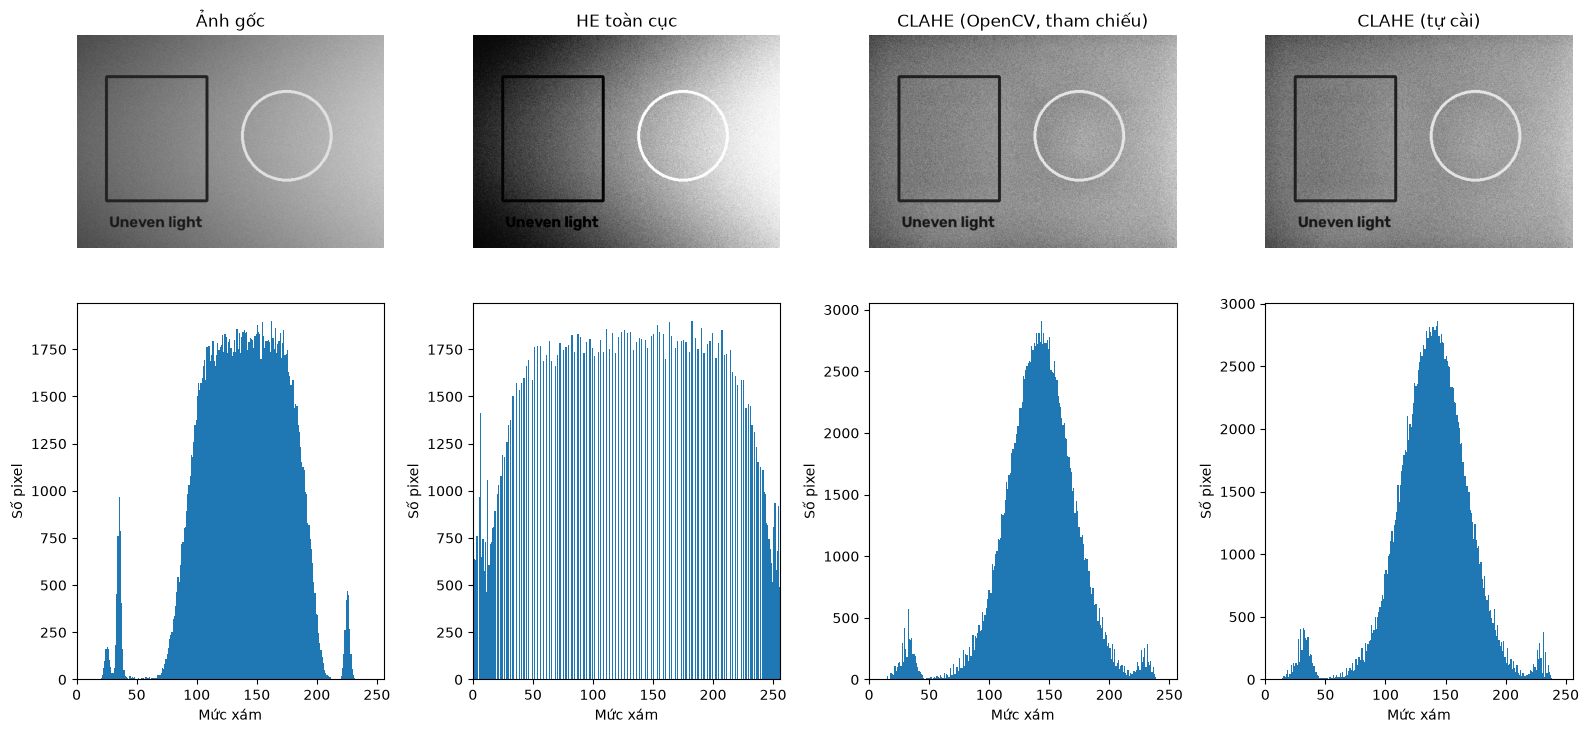

In [5]:
img1 = load_gray_image(IMAGE_PATH_1)

clip_limits = [1.0, 2.0, 4.0, 8.0]
fig, axes = plt.subplots(1, len(clip_limits), figsize=(16, 4))
fig.suptitle("Ảnh hưởng của clip_limit (grid cố định 8×8)")
for ax, clip_limit in zip(axes, clip_limits):
    result = my_clahe(img1, grid=(8, 8), clip_limit=clip_limit)
    if np.asarray(result).shape != img1.shape:
        raise ValueError("my_clahe phải trả ảnh cùng kích thước với ảnh đầu vào.")
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"clip_limit={clip_limit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Mốc tham chiếu cho phần thí nghiệm, không dùng thay cho mã thuật toán tự cài.
img_he = cv2.equalizeHist(img1)
img_clahe_cv = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img1)
img_my_clahe = my_clahe(img1, grid=(8, 8), clip_limit=2.0)

images = [img1, img_he, img_clahe_cv, img_my_clahe]
titles = ["Ảnh gốc", "HE toàn cục", "CLAHE (OpenCV, tham chiếu)", "CLAHE (tự cài)"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for index, (image, title) in enumerate(zip(images, titles)):
    axes[0, index].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, index].set_title(title)
    axes[0, index].axis("off")
    axes[1, index].hist(np.asarray(image).ravel(), bins=256, range=(0, 256))
    axes[1, index].set_xlim(0, 256)
    axes[1, index].set_xlabel("Mức xám")
    axes[1, index].set_ylabel("Số pixel")
plt.tight_layout()
plt.show()

## Thí nghiệm 2 — Ngưỡng thích nghi

Quét `radius` và ngưỡng `t`, so sánh ngưỡng cố định/Otsu/Bradley–Roth/Sauvola, rồi đo ba cách tính trung bình cục bộ: tích chập trực tiếp, tách nhân separable và ảnh tích phân. Thời gian thực nghiệm không phải chứng minh hình thức về độ phức tạp.

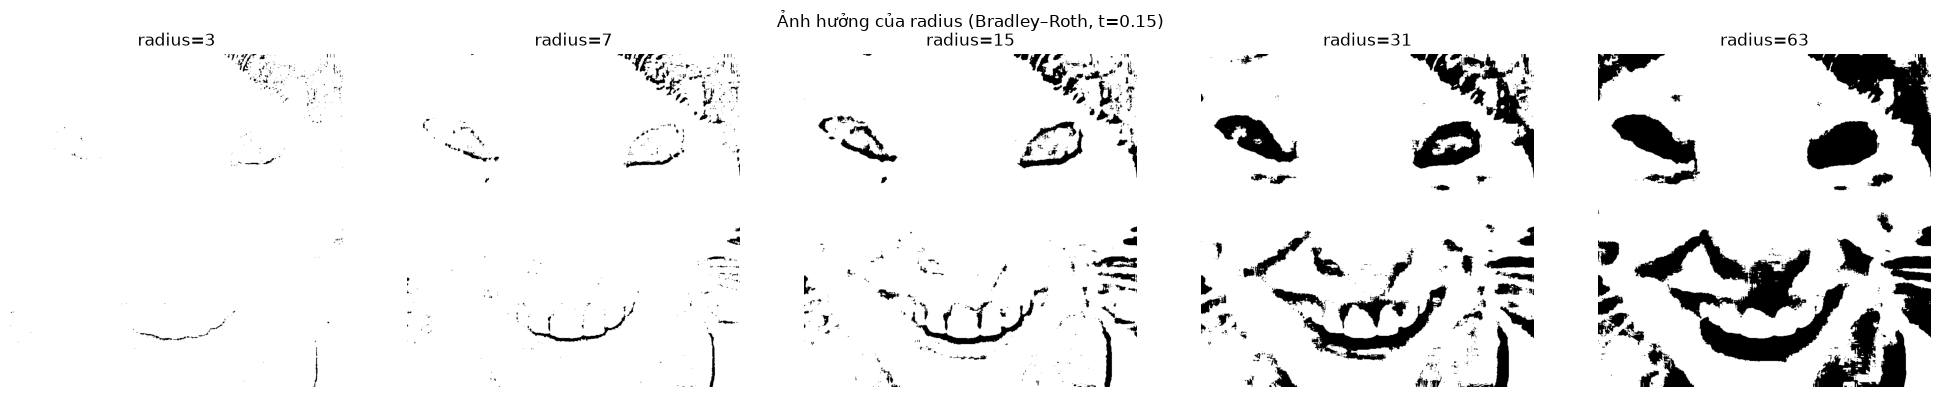

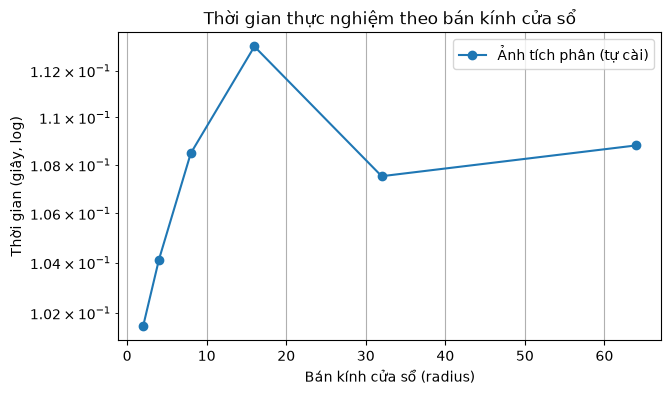

In [6]:
img2 = load_gray_image(IMAGE_PATH_2)

radii = [3, 7, 15, 31, 63]
fig, axes = plt.subplots(1, len(radii), figsize=(20, 4))
fig.suptitle("Ảnh hưởng của radius (Bradley–Roth, t=0.15)")
for ax, radius in zip(axes, radii):
    result = my_adaptive_threshold(img2, radius=radius, method="bradley", t=0.15)
    if np.asarray(result).shape != img2.shape:
        raise ValueError("my_adaptive_threshold phải trả ảnh cùng kích thước với ảnh đầu vào.")
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"radius={radius}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Đo lặp lại và lấy trung vị để giảm ảnh hưởng của dao động thời gian nhỏ.
radii_test = [2, 4, 8, 16, 32, 64]
repeat_count = 3
median_times = []
for radius in radii_test:
    elapsed = []
    for _ in range(repeat_count):
        start = time.perf_counter()
        my_adaptive_threshold(img2, radius=radius, method="bradley", t=0.15)
        elapsed.append(time.perf_counter() - start)
    median_times.append(float(np.median(elapsed)))

plt.figure(figsize=(7, 4))
plt.plot(radii_test, median_times, marker="o", label="Ảnh tích phân (tự cài)")
plt.yscale("log")
plt.xlabel("Bán kính cửa sổ (radius)")
plt.ylabel("Thời gian (giây, log)")
plt.title("Thời gian thực nghiệm theo bán kính cửa sổ")
plt.legend()
plt.grid(True)
plt.show()

## Thí nghiệm 3 — Hough đa tỉ lệ (khung kiểm thử)

Ô dưới tạo ảnh biên tổng hợp gồm các đoạn thẳng đã biết và gán hướng gradient chuẩn (`cv2.line` chỉ dựng dữ liệu). Cell so sánh Hough thô, Hough mịn và coarse-to-fine theo sai số góc, độ trội đỉnh và thời gian; đồng thời kiểm tra tắt/bật phiếu hướng gradient, biên góc 0/π và đoạn ngắn/dài. Đầu ra `(rho, theta)` theo $x\cos(\theta)+y\sin(\theta)=\rho$.

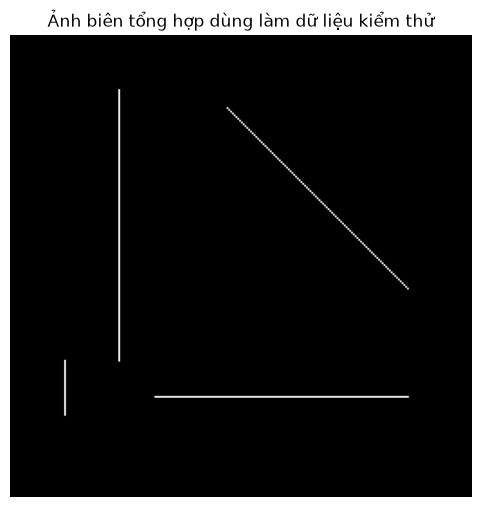

Các đường (rho, theta) do adapter trả về:
(60.09044073289977, 0.0)
(-56.599709735967814, 2.356194490192345)
(200.46769439523416, 1.5686146652299036)
(30.91790311568286, 0.004363323129985824)
(-24.68445490687585, 3.115412714809878)
(45.379502960115204, 0.074176493209759)
(-14.96027570113688, 3.0630528372500483)


In [7]:
height, width = 256, 256
synthetic_edges = np.zeros((height, width), dtype=np.uint8)
grad_dir = np.zeros((height, width), dtype=np.float64)

# (điểm đầu, điểm cuối, hướng pháp tuyến theta); chỉ tạo dữ liệu, không chạy Hough.
segments = [
    ((60, 30), (60, 180), 0.0),
    ((80, 200), (220, 200), np.pi / 2),
    ((120, 40), (220, 140), 3 * np.pi / 4),
    ((30, 210), (30, 180), np.deg2rad(179.5)),
]
for start_point, end_point, normal_theta in segments:
    mask = np.zeros_like(synthetic_edges)
    cv2.line(mask, start_point, end_point, color=255, thickness=1)
    synthetic_edges[mask > 0] = 255
    grad_dir[mask > 0] = normal_theta

plt.figure(figsize=(6, 6))
plt.imshow(synthetic_edges, cmap="gray")
plt.title("Ảnh biên tổng hợp dùng làm dữ liệu kiểm thử")
plt.axis("off")
plt.show()

detected_lines = my_hough_multiscale(synthetic_edges, grad_dir, n_levels=2, refine_factor=8)
print("Các đường (rho, theta) do adapter trả về:")
for line in detected_lines:
    print(line)

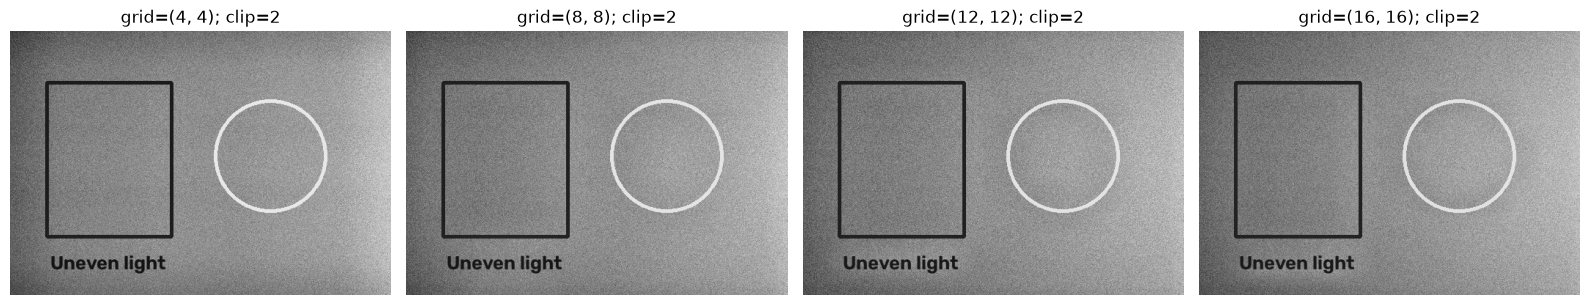

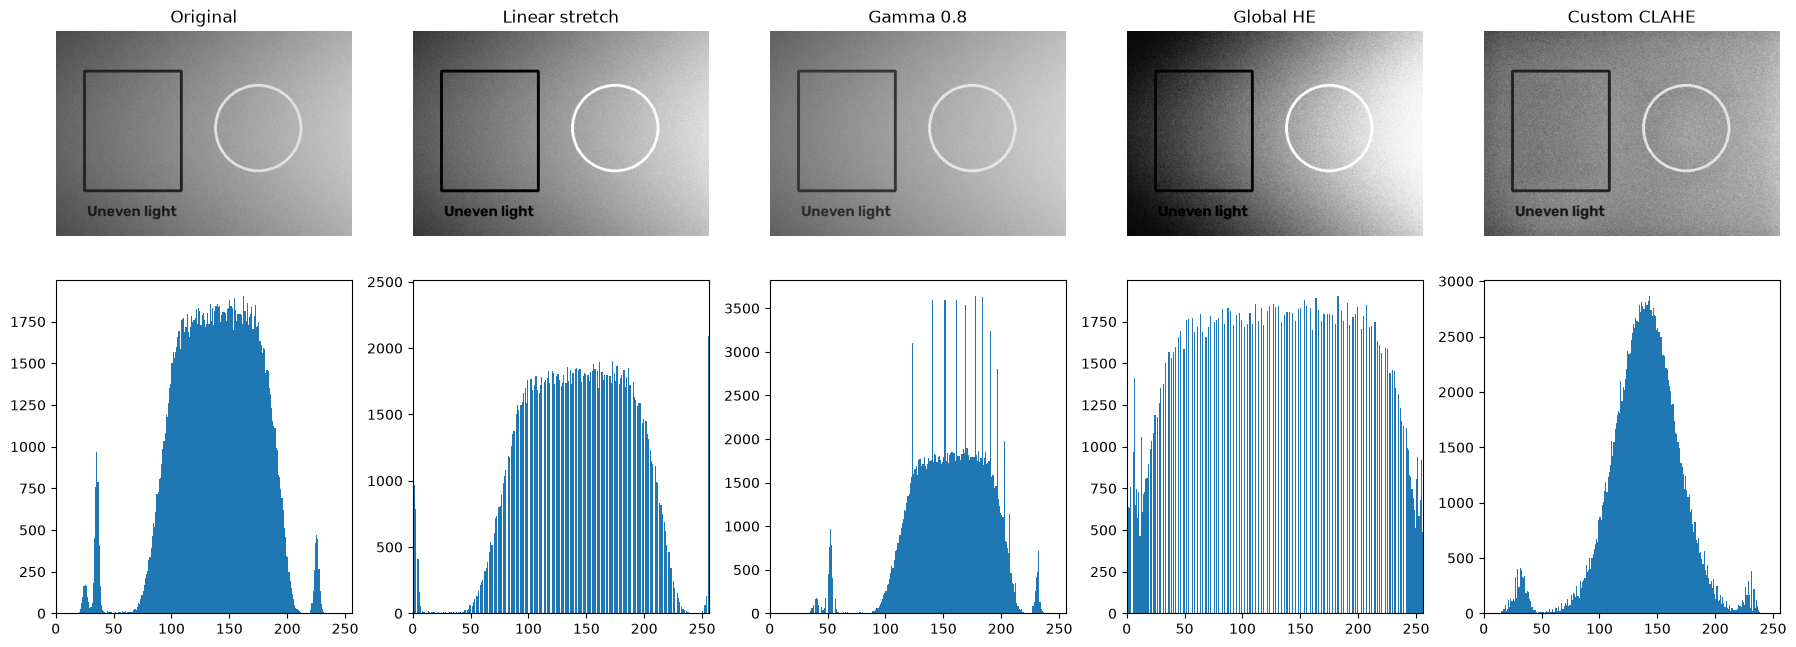

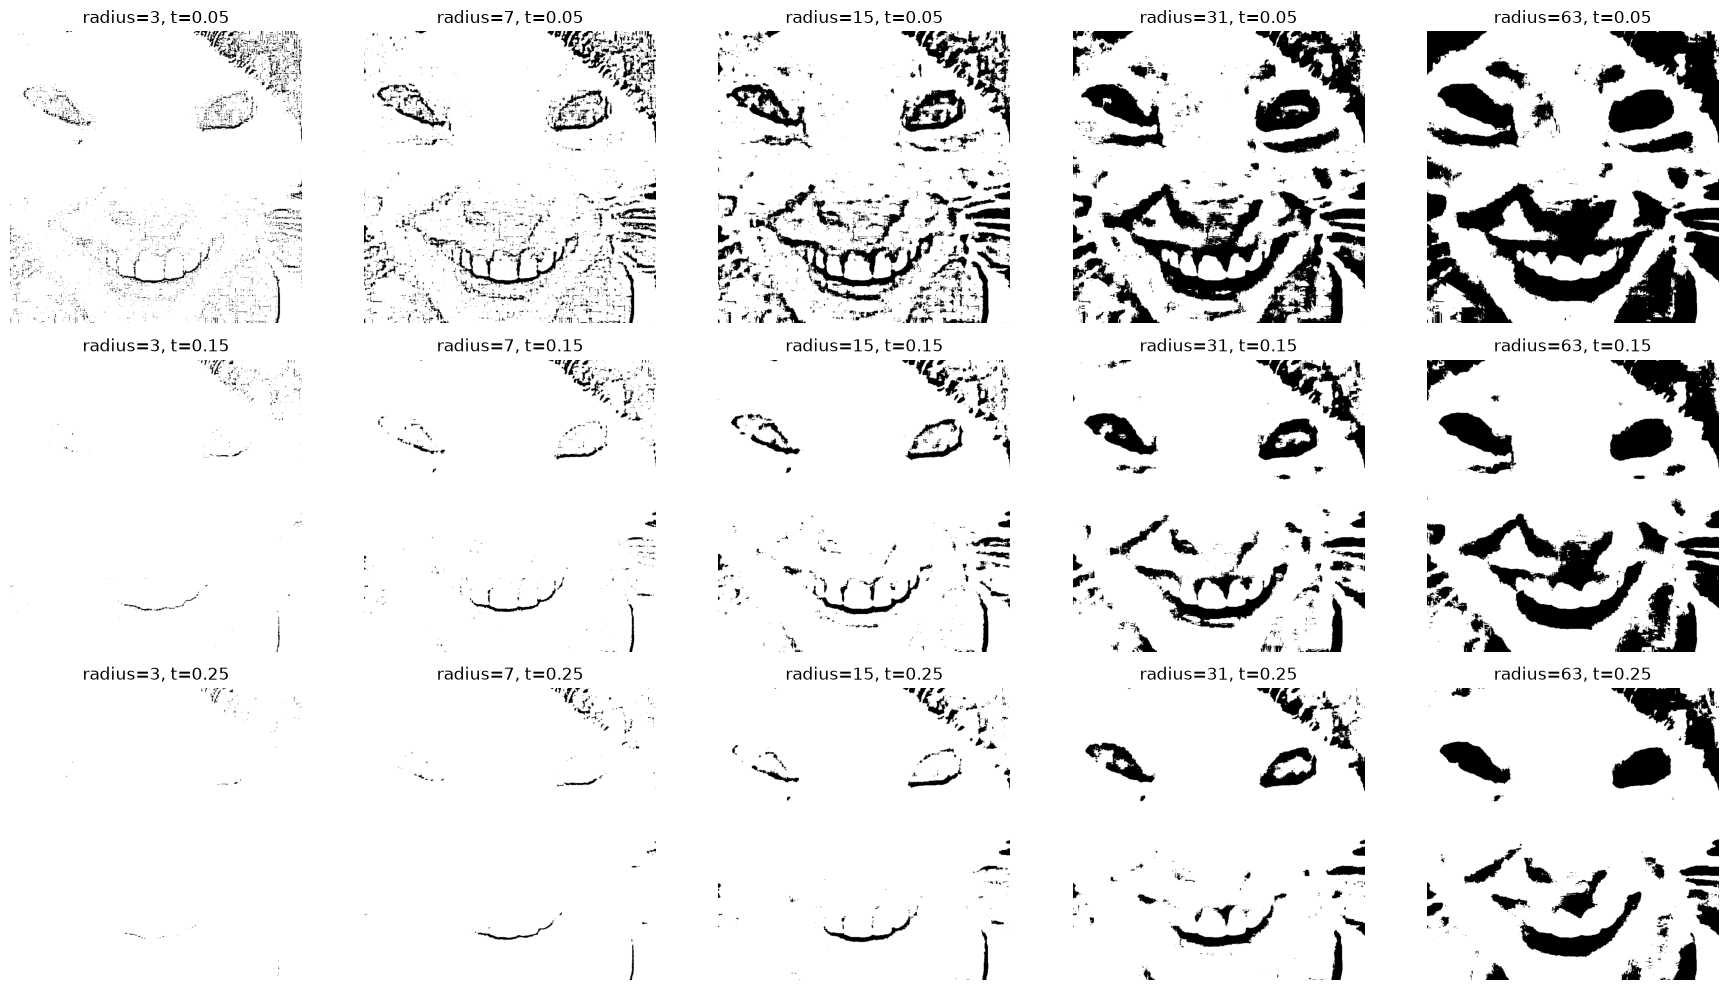

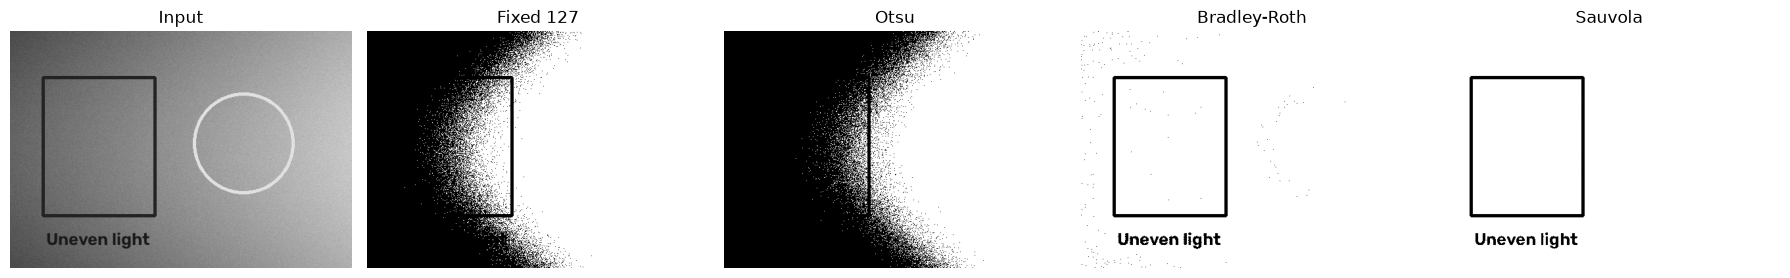

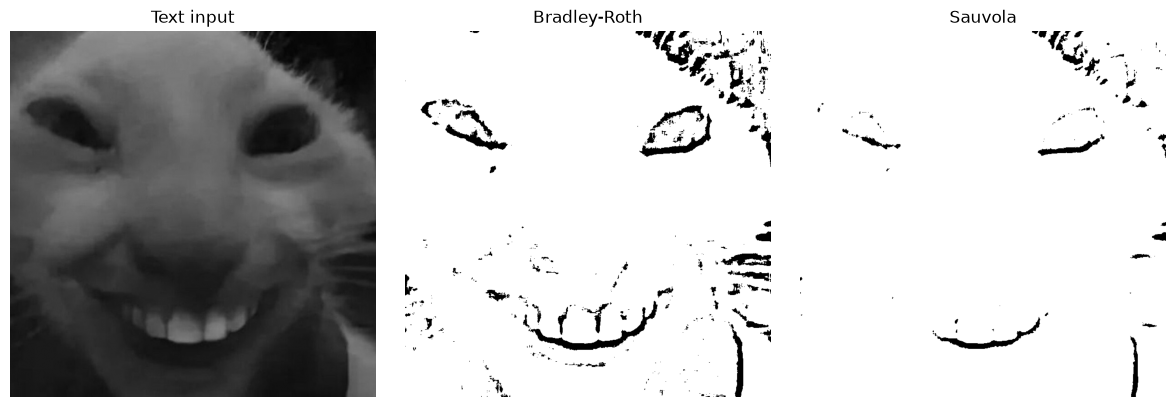

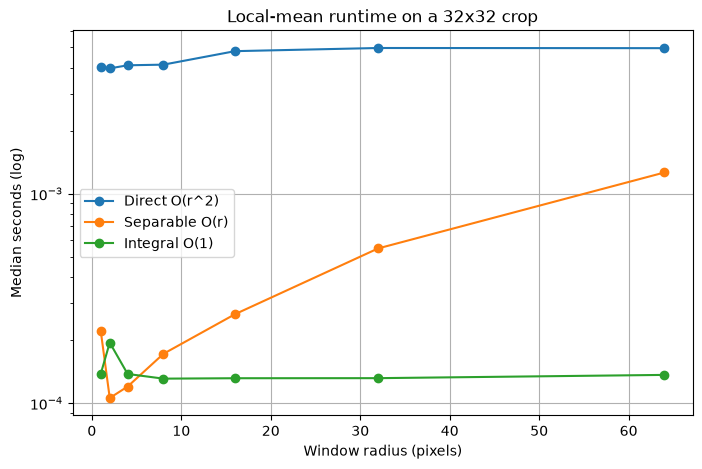

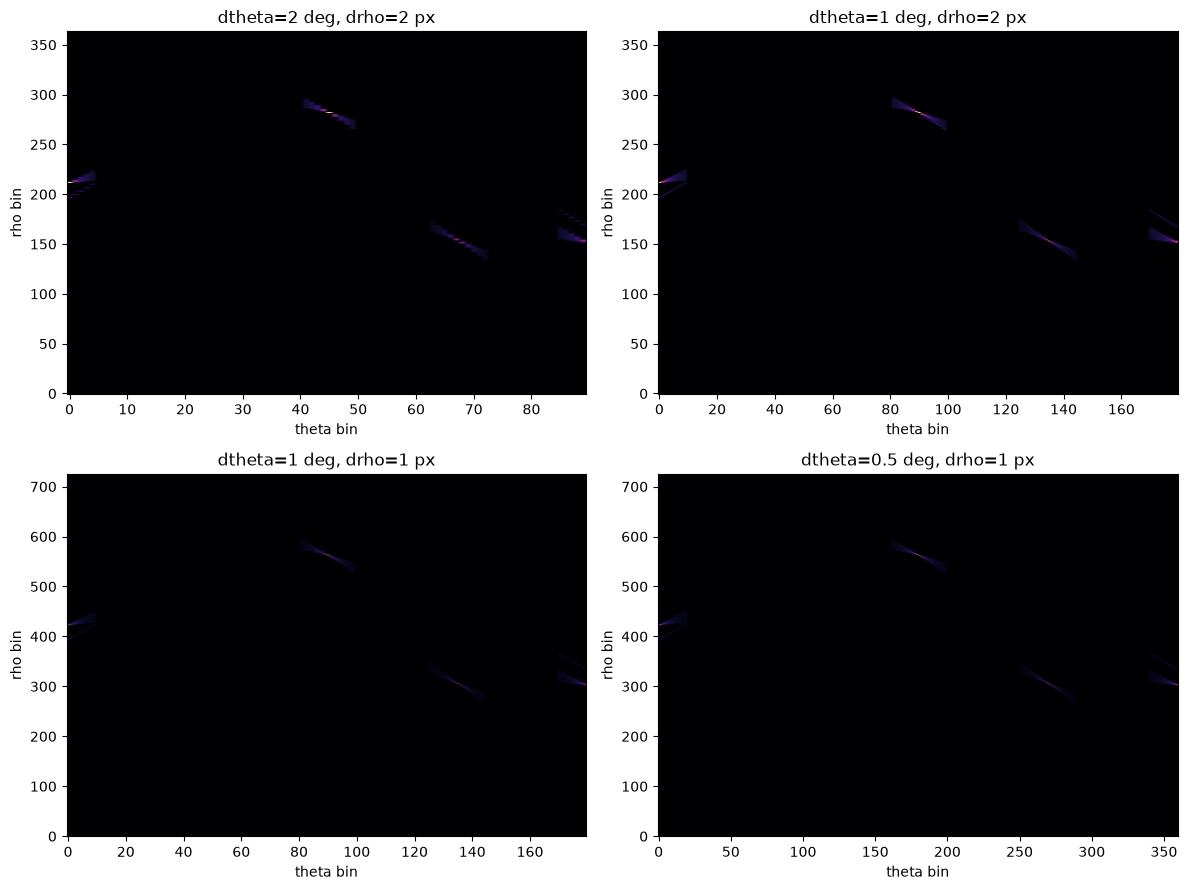

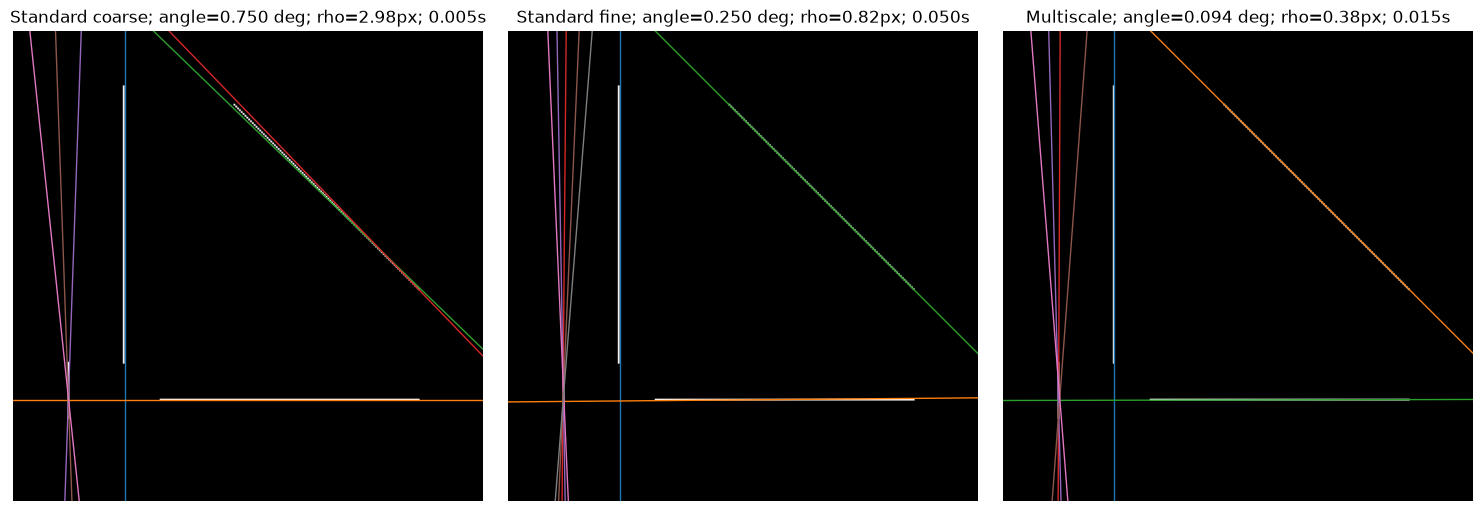

gradient=False: peak/background=129.63, runtime=0.0056s, peaks=[(60.83845451795662, 0.0, 151.0), (200.4676943952341, 1.5707963267948966, 143.0), (-52.85964081068363, 2.3387411976724017, 71.0)]
gradient=True: peak/background=151.00, runtime=0.0054s, peaks=[(60.83845451795662, 0.0, 151.0), (200.4676943952341, 1.5707963267948966, 141.0), (-52.85964081068363, 2.3387411976724017, 71.0)]
Truth (rho, theta deg): [(60.0, np.float64(0.0)), (200.0, np.float64(90.0)), (-56.57, np.float64(135.0)), (30.0, np.float64(0.0))]
Multiscale lines: [(60.09, np.float64(0.0)), (-56.6, np.float64(135.0)), (200.47, np.float64(89.88)), (30.92, np.float64(0.25)), (-24.68, np.float64(178.5)), (45.38, np.float64(4.25)), (-14.96, np.float64(175.5))]


In [8]:
from image_algorithms import box_sum, find_peaks, hough_accumulate, integral_image

# CLAHE: scan grid and compare all point-operation baselines on the same image.
img1 = load_gray_image(IMAGE_PATH_1)
grid_values = [(4, 4), (8, 8), (12, 12), (16, 16)]
fig, axes = plt.subplots(1, len(grid_values), figsize=(16, 4))
for ax, grid in zip(axes, grid_values):
    ax.imshow(my_clahe(img1, grid=grid, clip_limit=2.0), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"grid={grid}; clip=2")
    ax.axis("off")
plt.tight_layout()
plt.show()
low, high = np.percentile(img1, (1, 99))
linear = np.clip((img1.astype(float)-low)*255/max(high-low, 1), 0, 255).astype(np.uint8)
gamma = np.rint(255*(np.arange(256)/255.0)**0.8).astype(np.uint8)[img1]
clahe_baselines = [img1, linear, gamma, cv2.equalizeHist(img1), my_clahe(img1, (8, 8), 2.0)]
clahe_labels = ["Original", "Linear stretch", "Gamma 0.8", "Global HE", "Custom CLAHE"]
fig, axes = plt.subplots(2, len(clahe_baselines), figsize=(18, 7))
for i, (image, label) in enumerate(zip(clahe_baselines, clahe_labels)):
    axes[0, i].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(label)
    axes[0, i].axis("off")
    axes[1, i].hist(image.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_xlim(0, 256)
plt.tight_layout()
plt.show()

# Adaptive threshold: scan at least five radii and three t values.
img2 = load_gray_image(IMAGE_PATH_2)
radius_values = [3, 7, 15, 31, 63]
t_values = [0.05, 0.15, 0.25]
fig, axes = plt.subplots(len(t_values), len(radius_values), figsize=(18, 10))
for row, threshold_fraction in enumerate(t_values):
    for col, radius in enumerate(radius_values):
        axes[row, col].imshow(my_adaptive_threshold(img2, radius, "bradley", threshold_fraction), cmap="gray")
        axes[row, col].set_title(f"radius={radius}, t={threshold_fraction}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

# Fixed and Otsu baselines versus both adaptive methods on the uneven-light image.
fixed = np.where(img1 < 127, 0, 255).astype(np.uint8)
_, otsu = cv2.threshold(img1, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
threshold_images = [img1, fixed, otsu,
                    my_adaptive_threshold(img1, 15, "bradley", 0.15),
                    my_adaptive_threshold(img1, 15, "sauvola", 0.15, 0.34)]
threshold_labels = ["Input", "Fixed 127", "Otsu", "Bradley-Roth", "Sauvola"]
fig, axes = plt.subplots(1, len(threshold_images), figsize=(18, 4))
for ax, image, label in zip(axes, threshold_images, threshold_labels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Show Sauvola's response on a text image containing broad flat background.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img2, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Text input")
axes[1].imshow(my_adaptive_threshold(img2, 15, "bradley", 0.15), cmap="gray")
axes[1].set_title("Bradley-Roth")
axes[2].imshow(my_adaptive_threshold(img2, 15, "sauvola", 0.15, 0.34), cmap="gray")
axes[2].set_title("Sauvola")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Runtime comparison of direct O(r^2), separable O(r), and integral O(1) local means.
def mean_direct(image, radius):
    h, w = image.shape
    out = np.empty((h, w), dtype=np.float64)
    for y in range(h):
        for x in range(w):
            out[y, x] = image[max(0,y-radius):min(h,y+radius+1), max(0,x-radius):min(w,x+radius+1)].mean()
    return out

def mean_separable(image, radius):
    h, w = image.shape
    padded = np.pad(image.astype(float), ((radius, radius), (radius, radius)))
    counts = np.pad(np.ones(image.shape), ((radius, radius), (radius, radius)))
    horizontal = np.zeros((h+2*radius, w)); horizontal_count = np.zeros_like(horizontal)
    for dx in range(2*radius+1):
        horizontal += padded[:, dx:dx+w]
        horizontal_count += counts[:, dx:dx+w]
    sums = np.zeros((h, w)); number = np.zeros_like(sums)
    for dy in range(2*radius+1):
        sums += horizontal[dy:dy+h]
        number += horizontal_count[dy:dy+h]
    return sums / number

def mean_integral(image, radius):
    h, w = image.shape
    ys, xs = np.arange(h), np.arange(w)
    y1 = np.maximum(ys-radius, 0)[:, None]; y2 = np.minimum(ys+radius, h-1)[:, None]
    x1 = np.maximum(xs-radius, 0)[None, :]; x2 = np.minimum(xs+radius, w-1)[None, :]
    count = (y2-y1+1)*(x2-x1+1)
    return box_sum(integral_image(image), y1, x1, y2, x2) / count

small = img2[:min(32, img2.shape[0]), :min(32, img2.shape[1])]
radii = [1, 2, 4, 8, 16, 32, 64]
methods = [("Direct O(r^2)", mean_direct), ("Separable O(r)", mean_separable), ("Integral O(1)", mean_integral)]
curves = {name: [] for name, _ in methods}
for radius in radii:
    for name, method in methods:
        samples = []
        for _ in range(3):
            start = time.perf_counter(); method(small, radius); samples.append(time.perf_counter()-start)
        curves[name].append(float(np.median(samples)))
plt.figure(figsize=(8, 5))
for name, samples in curves.items():
    plt.plot(radii, samples, marker="o", label=name)
plt.yscale("log"); plt.xlabel("Window radius (pixels)"); plt.ylabel("Median seconds (log)")
plt.title("Local-mean runtime on a 32x32 crop"); plt.grid(True); plt.legend(); plt.show()

# Hough resolution sweep and standard coarse/fine versus multiscale comparison.
def make_accumulator(theta_step_deg, rho_step, gradient=True):
    diagonal = float(np.hypot(*synthetic_edges.shape))
    n_theta = max(2, int(np.ceil(180/theta_step_deg)))
    n_rho = max(2, int(np.ceil(2*diagonal/rho_step))+1)
    dt = np.pi/n_theta
    return hough_accumulate(synthetic_edges, (0, np.pi-dt), (-diagonal, diagonal), n_theta, n_rho,
                            grad_dir=grad_dir if gradient else None,
                            delta_deg=10.0 if gradient else None)

resolution_values = [(2, 2), (1, 2), (1, 1), (0.5, 1)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (dt, dr) in zip(axes.ravel(), resolution_values):
    accumulator, _, _ = make_accumulator(dt, dr)
    ax.imshow(accumulator, aspect="auto", origin="lower", cmap="magma")
    ax.set_title(f"dtheta={dt} deg, drho={dr} px")
    ax.set_xlabel("theta bin"); ax.set_ylabel("rho bin")
plt.tight_layout(); plt.show()

truth = [(60.0, 0.0), (200.0, np.pi/2), (-56.57, 3*np.pi/4), (30.0, 0.0)]
def standard_peaks(dt, dr):
    accumulator, thetas, rhos = make_accumulator(dt, dr)
    peaks = find_peaks(accumulator, 8, nms_radius=3, smooth_sigma=1.0, thetas=thetas, rhos=rhos)
    return accumulator, peaks

def mean_errors(peaks):
    angle_errors, rho_errors = [], []
    for true_rho, true_theta in truth:
        candidates = []
        for rho, theta, _ in peaks:
            da = abs(theta-true_theta); signed_rho = rho
            if da > np.pi/2:
                da = np.pi-da; signed_rho = -rho
            dr = abs(signed_rho-true_rho)
            candidates.append((np.rad2deg(da)+dr/10, np.rad2deg(da), dr))
        _, da, dr = min(candidates)
        angle_errors.append(da); rho_errors.append(dr)
    return np.mean(angle_errors), np.mean(rho_errors)

comparisons = [("Standard coarse", 2.0, 2.0), ("Standard fine", 0.5, 1.0)]
records = []
for label, dt, dr in comparisons:
    start = time.perf_counter(); accumulator, peaks = standard_peaks(dt, dr); elapsed = time.perf_counter()-start
    records.append((label, peaks, elapsed))
start = time.perf_counter()
multiscale_lines = my_hough_multiscale(synthetic_edges, grad_dir, n_levels=2, refine_factor=8)
multiscale_peaks = [(rho, theta, 0) for rho, theta in multiscale_lines]
records.append(("Multiscale", multiscale_peaks, time.perf_counter()-start))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (label, peaks, elapsed) in zip(axes, records):
    ax.imshow(synthetic_edges, cmap="gray")
    for rho, theta, _ in peaks[:8]:
        if abs(np.sin(theta)) > 1e-8:
            xs = np.array([0, width-1]); ys = (rho-xs*np.cos(theta))/np.sin(theta)
        else:
            xs = np.full(2, rho/np.cos(theta)); ys = np.array([0, height-1])
        ax.plot(xs, ys, linewidth=1)
    angle_error, rho_error = mean_errors(peaks)
    ax.set_title(f"{label}; angle={angle_error:.3f} deg; rho={rho_error:.2f}px; {elapsed:.3f}s")
    ax.set_xlim(0, width-1); ax.set_ylim(height-1, 0); ax.axis("off")
plt.tight_layout(); plt.show()

# Gradient weighting on/off: report peak-to-background ratio and runtime.
for enabled in (False, True):
    start = time.perf_counter(); accumulator, peaks = standard_peaks(2.0, 2.0) if enabled else (None, None)
    if not enabled:
        accumulator, thetas, rhos = make_accumulator(2.0, 2.0, gradient=False)
        peaks = find_peaks(accumulator, 8, nms_radius=3, smooth_sigma=1.0, thetas=thetas, rhos=rhos)
    elapsed = time.perf_counter()-start
    ratio = float(accumulator.max()/max(float(accumulator.mean()), 1.0))
    print(f"gradient={enabled}: peak/background={ratio:.2f}, runtime={elapsed:.4f}s, peaks={peaks[:3]}")
print("Truth (rho, theta deg):", [(rho, round(np.rad2deg(theta), 2)) for rho, theta in truth])
print("Multiscale lines:", [(round(rho, 2), round(np.rad2deg(theta), 2)) for rho, theta in multiscale_lines])